# 04 - Imbalanced Data

## Predicting Credit Card Fraud

### Objectives

- Analyze the impact of class imbalance.
- Compare class weighting strategies.
- Apply Random Undersampling.
- Apply Random Oversampling.
- Apply SMOTENC.
- Compare performance using the original validation distribution.
- Identify the most effective imbalance strategy.

### Experimental setup

- Models: Logistic Regression, LightGBM and XGBoost.
- Sampling strategy: 0.1.
- Stratified train/validation split: 80/20.
- Random state: 42.
- Validation data will never be resampled.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import time

from pathlib import Path

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.pipeline import Pipeline as SklearnPipeline

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from imblearn.pipeline import Pipeline as ImbPipeline

from imblearn.under_sampling import RandomUnderSampler

from imblearn.over_sampling import (
    RandomOverSampler,
    SMOTENC
)

from collections import Counter

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 5)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.5f}")

In [2]:
possible_paths = [
    Path.cwd() / "data" / "raw",
    Path.cwd().parent / "data" / "raw"
]

DATA_DIR = next(
    (path for path in possible_paths if path.exists()),
    None
)

if DATA_DIR is None:
    raise FileNotFoundError("Could not locate data/raw directory")

train = pd.read_csv(DATA_DIR / "train.csv")

print("Train shape:", train.shape)

Train shape: (699960, 26)


In [3]:
TARGET = "is_fraud"
ID_COL = "id"

X = train.drop(
    columns=[TARGET, ID_COL]
).copy()

y = train[TARGET].astype("int8").copy()

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)

print("\ny_train:", y_train.shape)
print("y_valid:", y_valid.shape)

X_train: (559968, 24)
X_valid: (139992, 24)

y_train: (559968,)
y_valid: (139992,)


In [4]:
train_counts = y_train.value_counts().sort_index()

valid_counts = y_valid.value_counts().sort_index()

imbalance_ratio = (
    train_counts[0] / train_counts[1]
)

print("TRAIN DISTRIBUTION")
print(train_counts)

print("\nVALIDATION DISTRIBUTION")
print(valid_counts)

print(f"\nImbalance ratio: {imbalance_ratio:.2f}:1")

print(f"Fraud percentage: {y_train.mean() * 100:.4f}%")

TRAIN DISTRIBUTION
is_fraud
0    550617
1      9351
Name: count, dtype: int64

VALIDATION DISTRIBUTION
is_fraud
0    137654
1      2338
Name: count, dtype: int64

Imbalance ratio: 58.88:1
Fraud percentage: 1.6699%


In [5]:
boolean_cols = [
    col for col in X.columns
    if pd.api.types.is_bool_dtype(X[col])
]

categorical_cols = [
    col for col in X.columns
    if (
        pd.api.types.is_string_dtype(X[col])
        or pd.api.types.is_object_dtype(X[col])
        or isinstance(X[col].dtype, pd.CategoricalDtype)
    )
]

numeric_cols = [
    col for col in X.columns
    if (
        pd.api.types.is_numeric_dtype(X[col])
        and not pd.api.types.is_bool_dtype(X[col])
    )
]

print("Numerical:", len(numeric_cols))
print("Categorical:", len(categorical_cols))
print("Boolean:", len(boolean_cols))

assert len(numeric_cols) == 13
assert len(categorical_cols) == 5
assert len(boolean_cols) == 6

Numerical: 13
Categorical: 5
Boolean: 6


In [6]:
def create_preprocessor(scale_numeric=True):

    numerical_transformer = (
        RobustScaler()
        if scale_numeric
        else "passthrough"
    )

    try:
        categorical_transformer = OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
            dtype=np.float32
        )

    except TypeError:
        categorical_transformer = OneHotEncoder(
            handle_unknown="ignore",
            sparse=False,
            dtype=np.float32
        )

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "num",
                numerical_transformer,
                numeric_cols
            ),
            (
                "cat",
                categorical_transformer,
                categorical_cols
            ),
            (
                "bool",
                "passthrough",
                boolean_cols
            )
        ],
        remainder="drop",
        verbose_feature_names_out=False
    )

    return preprocessor

In [7]:
class DataFrameNumericScaler(BaseEstimator, TransformerMixin):

    def __init__(self, columns):
        self.columns = columns

    def fit(self, X, y=None):

        self.scaler_ = RobustScaler()

        self.scaler_.fit(
            X[self.columns]
        )

        return self

    def transform(self, X):

        X_transformed = X.copy()

        scaled_values = self.scaler_.transform(
            X_transformed[self.columns]
        )

        for i, col in enumerate(self.columns):

            X_transformed[col] = scaled_values[:, i]

        return X_transformed

In [8]:
def create_logistic(weighted=False):

    return LogisticRegression(
        solver="lbfgs",
        max_iter=500,
        class_weight="balanced" if weighted else None,
        random_state=42
    )


def create_lightgbm(weighted=False):

    return LGBMClassifier(
        objective="binary",
        n_estimators=200,
        learning_rate=0.1,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=20,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        scale_pos_weight=imbalance_ratio if weighted else 1.0,
        n_jobs=-1,
        random_state=42,
        verbosity=-1
    )


def create_xgboost(weighted=False):

    return XGBClassifier(
        objective="binary:logistic",
        eval_metric="auc",
        n_estimators=200,
        learning_rate=0.1,
        max_depth=6,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        scale_pos_weight=imbalance_ratio if weighted else 1.0,
        tree_method="hist",
        n_jobs=-1,
        random_state=42,
        verbosity=0
    )


model_factories = {
    "Logistic Regression": create_logistic,
    "LightGBM": create_lightgbm,
    "XGBoost": create_xgboost
}

In [9]:
SAMPLING_RATIO = 0.1


def create_sampler(strategy):

    if strategy == "Random Undersampling":

        return RandomUnderSampler(
            sampling_strategy=SAMPLING_RATIO,
            random_state=42
        )

    elif strategy == "Random Oversampling":

        return RandomOverSampler(
            sampling_strategy=SAMPLING_RATIO,
            random_state=42
        )

    elif strategy == "SMOTENC":

        return SMOTENC(
            categorical_features=categorical_cols + boolean_cols,
            sampling_strategy=SAMPLING_RATIO,
            random_state=42,
            k_neighbors=5
        )

    return None


def build_pipeline(model_name, estimator, strategy):

    steps = []

    if strategy == "SMOTENC":

        # Scale numerical variables while preserving categories
        steps.append((
            "numeric_scaling",
            DataFrameNumericScaler(numeric_cols)
        ))

        # Generate synthetic mixed-type samples
        steps.append((
            "sampler",
            create_sampler(strategy)
        ))

        # Numerical variables are already scaled
        steps.append((
            "preprocessing",
            create_preprocessor(scale_numeric=False)
        ))

    else:

        # Apply Random Under/Over Sampling before encoding
        if strategy in [
            "Random Undersampling",
            "Random Oversampling"
        ]:

            steps.append((
                "sampler",
                create_sampler(strategy)
            ))

        # Logistic Regression requires scaling
        scale_numeric = (
            model_name == "Logistic Regression"
        )

        steps.append((
            "preprocessing",
            create_preprocessor(
                scale_numeric=scale_numeric
            )
        ))

    steps.append((
        "classifier",
        estimator
    ))

    return ImbPipeline(steps)

In [10]:
experiment_specs = []

# 1. Baseline: original data
for model_name, factory in model_factories.items():

    experiment_specs.append({
        "model": model_name,
        "strategy": "Baseline",
        "estimator": factory(weighted=False)
    })


# 2. Class weighting
for model_name, factory in model_factories.items():

    experiment_specs.append({
        "model": model_name,
        "strategy": "Class Weighting",
        "estimator": factory(weighted=True)
    })


# 3. Resampling techniques
sampling_strategies = [
    "Random Undersampling",
    "Random Oversampling",
    "SMOTENC"
]

for strategy in sampling_strategies:

    for model_name, factory in model_factories.items():

        experiment_specs.append({
            "model": model_name,
            "strategy": strategy,
            "estimator": factory(weighted=False)
        })


print("Total experiments:", len(experiment_specs))

for experiment in experiment_specs:

    print(
        experiment["strategy"],
        "-",
        experiment["model"]
    )

Total experiments: 15
Baseline - Logistic Regression
Baseline - LightGBM
Baseline - XGBoost
Class Weighting - Logistic Regression
Class Weighting - LightGBM
Class Weighting - XGBoost
Random Undersampling - Logistic Regression
Random Undersampling - LightGBM
Random Undersampling - XGBoost
Random Oversampling - Logistic Regression
Random Oversampling - LightGBM
Random Oversampling - XGBoost
SMOTENC - Logistic Regression
SMOTENC - LightGBM
SMOTENC - XGBoost


In [11]:
fitted_models = {}
valid_probabilities = {}
experiment_results = []


def get_resampled_counts(model, strategy):

    if strategy in ["Baseline", "Class Weighting"]:
        return y_train.value_counts().to_dict()

    sampler = model.named_steps["sampler"]

    # Random Under/Over Sampling
    if hasattr(sampler, "sample_indices_"):

        sampled_y = y_train.iloc[
            sampler.sample_indices_
        ]

        return sampled_y.value_counts().to_dict()

    # SMOTENC: add generated minority observations
    counts = y_train.value_counts().to_dict()

    for class_label, generated_count in sampler.sampling_strategy_.items():

        counts[class_label] += int(generated_count)

    return counts


for i, experiment in enumerate(experiment_specs, start=1):

    model_name = experiment["model"]
    strategy = experiment["strategy"]
    estimator = experiment["estimator"]

    experiment_name = f"{strategy} | {model_name}"

    print("\n" + "=" * 60)
    print(f"Experiment {i}/{len(experiment_specs)}")
    print(experiment_name)
    print("=" * 60)

    # Build pipeline
    model = build_pipeline(
        model_name,
        estimator,
        strategy
    )

    # Training
    start_time = time.perf_counter()

    model.fit(X_train, y_train)

    fit_time = time.perf_counter() - start_time

    # Validation predictions
    start_time = time.perf_counter()

    y_proba = model.predict_proba(X_valid)[:, 1]

    predict_time = time.perf_counter() - start_time

    # Default threshold
    y_pred = (y_proba >= 0.5).astype("int8")

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_valid,
        y_pred,
        labels=[0, 1]
    ).ravel()

    # Metrics
    roc_auc = roc_auc_score(y_valid, y_proba)

    avg_precision = average_precision_score(
        y_valid,
        y_proba
    )

    accuracy = accuracy_score(y_valid, y_pred)

    precision = precision_score(
        y_valid,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_valid,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_valid,
        y_pred,
        zero_division=0
    )

    # Resampled training distribution
    resampled_counts = get_resampled_counts(
        model,
        strategy
    )

    total_training_rows = sum(
        resampled_counts.values()
    )

    fraud_percentage = (
        resampled_counts.get(1, 0) /
        total_training_rows * 100
    )

    # Store results
    fitted_models[experiment_name] = model

    valid_probabilities[experiment_name] = y_proba

    experiment_results.append({

        "experiment": experiment_name,
        "model": model_name,
        "strategy": strategy,

        "roc_auc": roc_auc,
        "average_precision": avg_precision,

        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,

        "true_positives": tp,
        "false_positives": fp,
        "false_negatives": fn,
        "true_negatives": tn,

        "predicted_frauds": int(y_pred.sum()),

        "training_rows_after_sampling": total_training_rows,
        "training_fraud_percentage": fraud_percentage,

        "fit_time_seconds": fit_time,
        "predict_time_seconds": predict_time
    })

    print(f"ROC-AUC: {roc_auc:.5f}")
    print(f"Average Precision: {avg_precision:.5f}")
    print(f"Precision: {precision:.5f}")
    print(f"Recall: {recall:.5f}")
    print(f"F1-Score: {f1:.5f}")

    print(
        f"Training rows after sampling: "
        f"{total_training_rows:,}"
    )

    print(f"Fit time: {fit_time:.2f} seconds")
    print("Experiment completed.")


Experiment 1/15
Baseline | Logistic Regression
ROC-AUC: 0.94028
Average Precision: 0.49698
Precision: 0.76541
Recall: 0.30282
F1-Score: 0.43396
Training rows after sampling: 559,968
Fit time: 3.40 seconds
Experiment completed.

Experiment 2/15
Baseline | LightGBM
ROC-AUC: 0.94423
Average Precision: 0.50289
Precision: 0.74557
Recall: 0.30582
F1-Score: 0.43373
Training rows after sampling: 559,968
Fit time: 1.72 seconds
Experiment completed.

Experiment 3/15
Baseline | XGBoost
ROC-AUC: 0.94386
Average Precision: 0.50234
Precision: 0.74520
Recall: 0.31523
F1-Score: 0.44304
Training rows after sampling: 559,968
Fit time: 3.21 seconds
Experiment completed.

Experiment 4/15
Class Weighting | Logistic Regression
ROC-AUC: 0.94007
Average Precision: 0.49391
Precision: 0.10718
Recall: 0.84303
F1-Score: 0.19019
Training rows after sampling: 559,968
Fit time: 4.76 seconds
Experiment completed.

Experiment 5/15
Class Weighting | LightGBM
ROC-AUC: 0.93871
Average Precision: 0.47286
Precision: 0.111

In [12]:
results_df = pd.DataFrame(experiment_results)

results_df = results_df.sort_values(
    "average_precision",
    ascending=False
)

display(results_df)

,experiment,model,strategy,roc_auc,average_precision,accuracy,precision,recall,f1_score,true_positives,false_positives,false_negatives,true_negatives,predicted_frauds,training_rows_after_sampling,training_fraud_percentage,fit_time_seconds,predict_time_seconds
10,Random Oversampling | LightGBM,LightGBM,Random Oversampling,0.94364,0.50449,0.97936,0.41190,0.55090,0.47136,1288,1839,1050,135815,3127,605678,9.09080,2.52453,0.24682
1,Baseline | LightGBM,LightGBM,Baseline,0.94423,0.50289,0.98666,0.74557,0.30582,0.43373,715,244,1623,137410,959,559968,1.66992,1.71584,0.24400
2,Baseline | XGBoost,XGBoost,Baseline,0.94386,0.50234,0.98676,0.74520,0.31523,0.44304,737,252,1601,137402,989,559968,1.66992,3.20851,0.17267
11,Random Oversampling | XGBoost,XGBoost,Random Oversampling,0.94297,0.50142,0.98023,0.42566,0.52652,0.47075,1231,1661,1107,135993,2892,605678,9.09080,4.09741,0.16852
7,Random Undersampling | LightGBM,LightGBM,Random Undersampling,0.94406,0.49873,0.97741,0.38106,0.56459,0.45502,1320,2144,1018,135510,3464,102861,9.09091,0.52101,0.25159
13,SMOTENC | LightGBM,LightGBM,SMOTENC,0.94212,0.49780,0.98667,0.75652,0.29769,0.42726,696,224,1642,137430,920,605678,9.09080,25.94472,0.30849
8,Random Undersampling | XGBoost,XGBoost,Random Undersampling,0.94325,0.49749,0.97792,0.38838,0.56031,0.45876,1310,2063,1028,135591,3373,102861,9.09091,0.75164,0.18535
0,Baseline | Logistic Regression,Logistic Regression,Baseline,0.94028,0.49698,0.98681,0.76541,0.30282,0.43396,708,217,1630,137437,925,559968,1.66992,3.39614,0.10784
6,Random Undersampling | Logistic Regression,Logistic Regression,Random Undersampling,0.94024,0.49667,0.97881,0.40126,0.54577,0.46249,1276,1904,1062,135750,3180,102861,9.09091,0.83277,0.10519
9,Random Oversampling | Logistic Regression,Logistic Regression,Random Oversampling,0.94029,0.49640,0.97869,0.39912,0.54577,0.46107,1276,1921,1062,135733,3197,605678,9.09080,3.96282,0.11053


In [13]:
strategy_comparison = (
    results_df
    .sort_values("average_precision", ascending=False)
    .groupby("strategy", sort=False)
    .first()
    [
        [
            "model",
            "roc_auc",
            "average_precision",
            "precision",
            "recall",
            "f1_score",
            "false_positives",
            "false_negatives",
            "fit_time_seconds"
        ]
    ]
)

display(
    strategy_comparison.sort_values(
        "average_precision",
        ascending=False
    )
)

,model,roc_auc,average_precision,precision,recall,f1_score,false_positives,false_negatives,fit_time_seconds
strategy,,,,,,,,,
Random Oversampling,LightGBM,0.94364,0.50449,0.41190,0.55090,0.47136,1839,1050,2.52453
Baseline,LightGBM,0.94423,0.50289,0.74557,0.30582,0.43373,244,1623,1.71584
Random Undersampling,LightGBM,0.94406,0.49873,0.38106,0.56459,0.45502,2144,1018,0.52101
SMOTENC,LightGBM,0.94212,0.49780,0.75652,0.29769,0.42726,224,1642,25.94472
Class Weighting,Logistic Regression,0.94007,0.49391,0.10718,0.84303,0.19019,16418,367,4.75685


In [14]:
strategy_matrix = results_df.pivot(
    index="model",
    columns="strategy",
    values="average_precision"
)

display(strategy_matrix)

strategy,Baseline,Class Weighting,Random Oversampling,Random Undersampling,SMOTENC
model,,,,,
LightGBM,0.50289,0.47286,0.50449,0.49873,0.49780
Logistic Regression,0.49698,0.49391,0.49640,0.49667,0.40854
XGBoost,0.50234,0.48843,0.50142,0.49749,0.48128


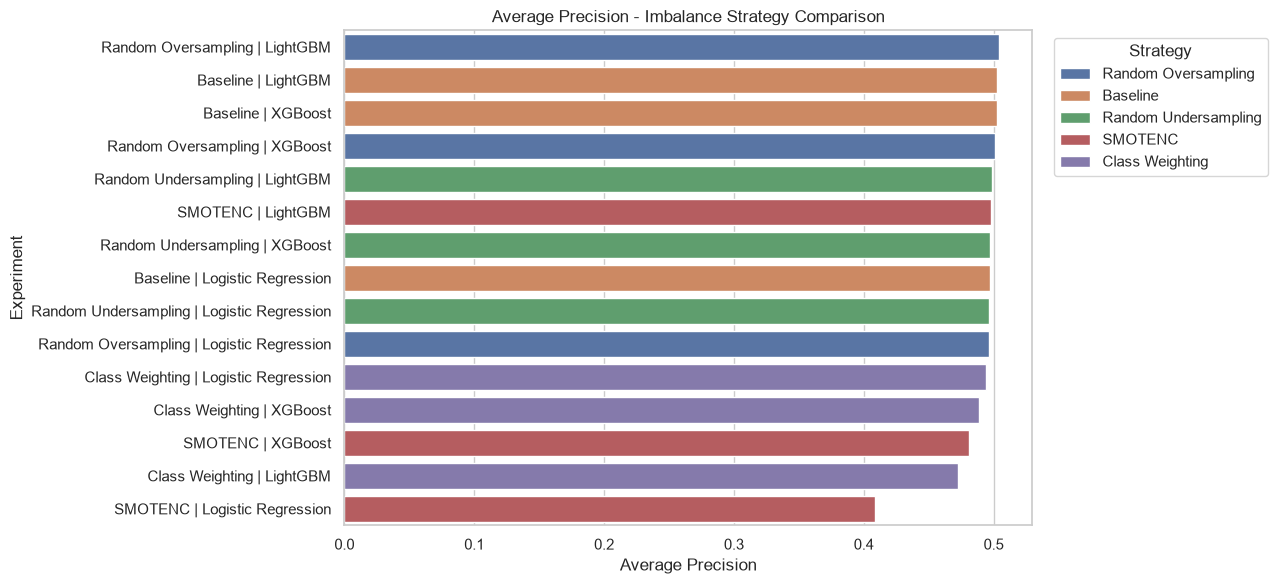

In [15]:
plt.figure(figsize=(13, 6))

plot_data = results_df.sort_values(
    "average_precision",
    ascending=False
)

sns.barplot(
    data=plot_data,
    x="average_precision",
    y="experiment",
    hue="strategy"
)

plt.title("Average Precision - Imbalance Strategy Comparison")
plt.xlabel("Average Precision")
plt.ylabel("Experiment")

plt.legend(
    title="Strategy",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

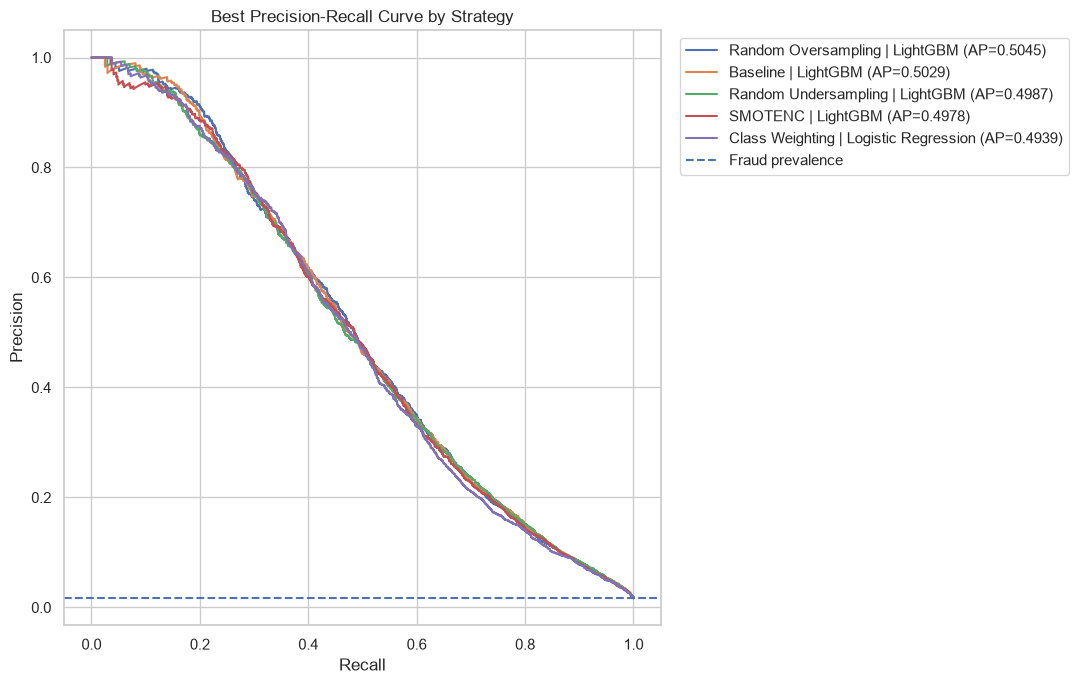

In [16]:
best_per_strategy = (
    results_df
    .sort_values("average_precision", ascending=False)
    .groupby("strategy", sort=False)
    .head(1)
)

plt.figure(figsize=(11, 7))

for _, row in best_per_strategy.iterrows():

    name = row["experiment"]

    y_proba = valid_probabilities[name]

    precision_values, recall_values, thresholds = (
        precision_recall_curve(y_valid, y_proba)
    )

    plt.plot(
        recall_values,
        precision_values,
        label=(
            f"{name} "
            f"(AP={row['average_precision']:.4f})"
        )
    )

plt.axhline(
    y=y_valid.mean(),
    linestyle="--",
    label="Fraud prevalence"
)

plt.title("Best Precision-Recall Curve by Strategy")
plt.xlabel("Recall")
plt.ylabel("Precision")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

Top 3 experiments:
['Random Oversampling | LightGBM', 'Baseline | LightGBM', 'Baseline | XGBoost']


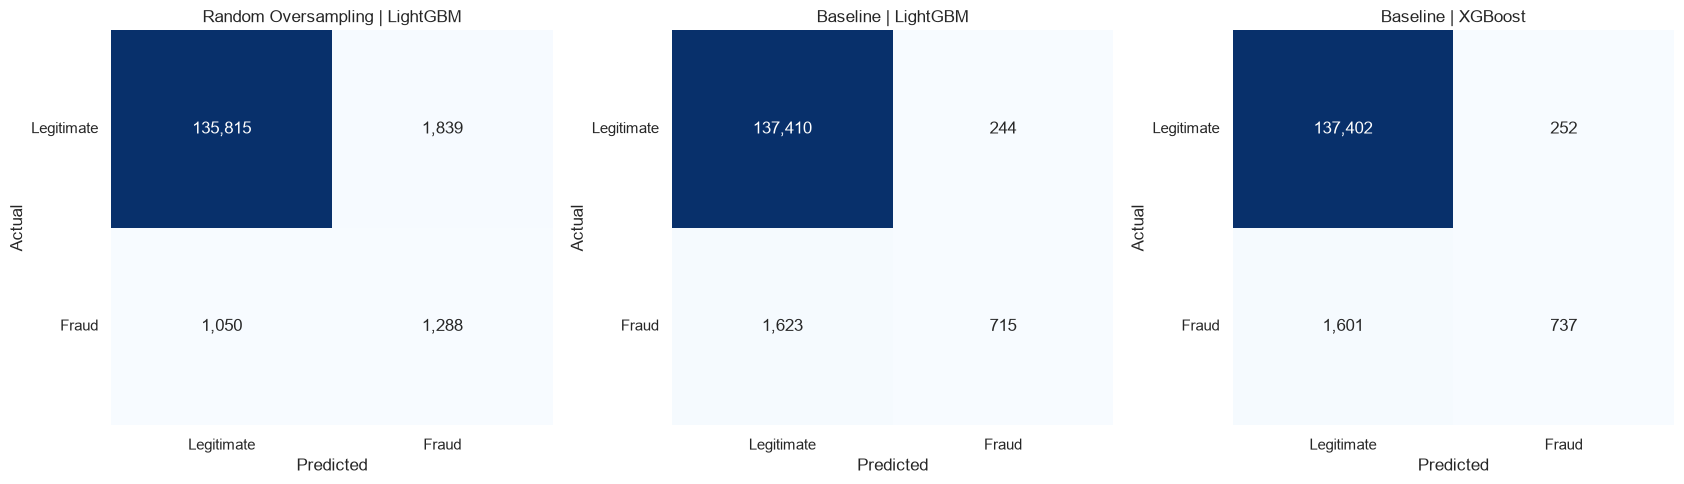

In [17]:
top_3_experiments = (
    results_df.head(3)["experiment"].tolist()
)

print("Top 3 experiments:")
print(top_3_experiments)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5)
)

for ax, name in zip(axes, top_3_experiments):

    y_proba = valid_probabilities[name]

    y_pred = (
        y_proba >= 0.5
    ).astype("int8")

    cm = confusion_matrix(
        y_valid,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt=",",
        cmap="Blues",
        cbar=False,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

    ax.set_xticklabels(
        ["Legitimate", "Fraud"]
    )

    ax.set_yticklabels(
        ["Legitimate", "Fraud"],
        rotation=0
    )

plt.tight_layout()
plt.show()

# Imbalanced Data - Conclusions

## 1. Baseline Performance

- Best baseline model: LightGBM.
- ROC-AUC: 0.94423.
- Average Precision: 0.50289.
- Recall: 30.58%.

## 2. Class Weighting

- Highest Recall: Logistic Regression (84.30%).
- LightGBM Recall: 83.49%.
- XGBoost Recall: 81.82%.
- Significant increase in false positives.
- Average Precision decreased compared with baseline models.

Class weighting substantially increases fraud detection,
but generates many false alarms at the default threshold.

## 3. Random Undersampling

- Best model: LightGBM.
- ROC-AUC: 0.94406.
- Average Precision: 0.49873.
- Recall: 56.46%.
- F1-Score: 0.45502.

Undersampling improves Recall and reduces training time,
but removes a considerable number of legitimate transactions.

## 4. Random Oversampling

- Best model: LightGBM.
- ROC-AUC: 0.94364.
- Average Precision: 0.50449.
- Recall: 55.09%.
- F1-Score: 0.47136.

Random Oversampling achieves the best Average Precision
and F1-Score among the tested experiments.

It provides a better Recall than baseline models,
although Precision decreases.

## 5. SMOTENC

- Best model: LightGBM.
- ROC-AUC: 0.94212.
- Average Precision: 0.49780.
- Recall: 29.77%.

SMOTENC did not improve the main evaluation metrics
and required considerably more training time.

## 6. Strategy Comparison

- Best ROC-AUC: LightGBM Baseline (0.94423).
- Best Average Precision: LightGBM Random Oversampling (0.50449).
- Best Recall: Logistic Regression Class Weighting (84.30%).
- Best F1-Score: LightGBM Random Oversampling (0.47136).

## 7. Model Selection

Selected candidates:

- LightGBM Baseline.
- LightGBM with Random Oversampling.
- XGBoost Baseline.
- XGBoost with Random Oversampling.
- LightGBM with Random Undersampling.

Class Weighting remains an alternative when prioritizing Recall.

SMOTENC was discarded due to its lower predictive performance
and higher computational cost.

## 8. Limitations

- No hyperparameter tuning.
- Default classification threshold of 0.5.
- Potential probability calibration issues.
- The availability of `is_ai_generated_scam_attempt`
  still requires investigation.

## 9. Next Steps

- Feature Engineering.
- Investigate feature interactions.
- Explore transformations for skewed numerical features.
- Re-evaluate selected models using engineered features.